<div style="border-left:7px solid #1A59FD; background:#F3F6FF; padding:16px 20px; border-radius:4px; font-family:Segoe UI, Arial, sans-serif;">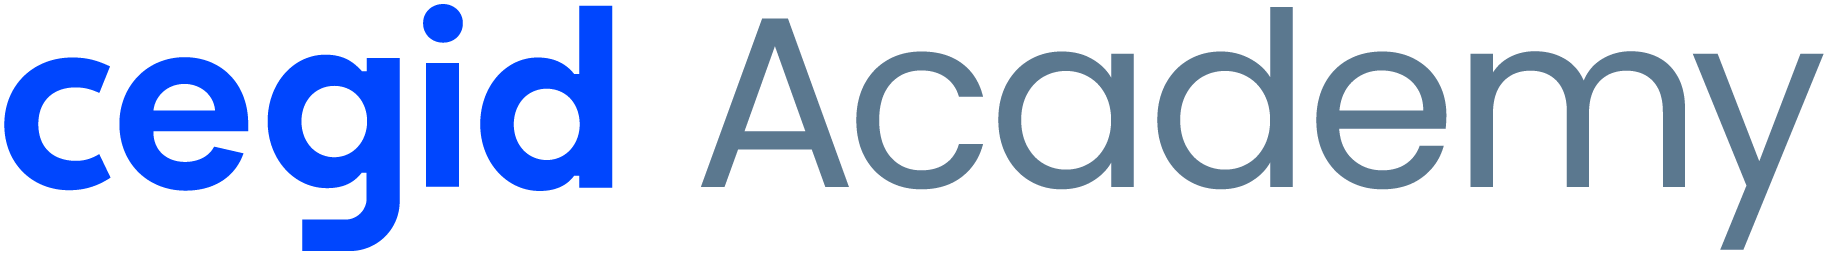<div style="font-size:22px; font-weight:700; color:#1A59FD; line-height:1.2;">Fase 5 &middot; Avaliação</div><div style="font-size:14px; color:#0A2540; margin-top:4px;">Implementação de Modelos Analíticos com Python &nbsp;&middot;&nbsp; Projeto CRISP-DM · <i>Evaluation</i> &nbsp;&middot;&nbsp; Versão <b>formandos</b> &nbsp;&middot;&nbsp; Apoio: <b>M5</b></div><div style="margin-top:10px;"><span style="display:inline-block;background:#D6E2FF;color:#1A59FD;border:1px solid #D6E2FF;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">1. Entendimento do Negócio</span><span style="display:inline-block;background:#D6E2FF;color:#1A59FD;border:1px solid #D6E2FF;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">2. Entendimento dos Dados</span><span style="display:inline-block;background:#D6E2FF;color:#1A59FD;border:1px solid #D6E2FF;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">3. Preparação dos Dados</span><span style="display:inline-block;background:#D6E2FF;color:#1A59FD;border:1px solid #D6E2FF;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">4. Modelação</span><span style="display:inline-block;background:#1A59FD;color:#FFFFFF;font-weight:600;border:1px solid #1A59FD;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">5. Avaliação</span><span style="display:inline-block;background:#FFFFFF;color:#0A2540;border:1px solid #C9D6F5;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">6. Deployment</span></div></div>

#### Identificação do projeto

| Campo | Preenchimento |
|---|---|
| **Projeto** | |
| **Grupo** | |
| **Formandos** | |
| **Data** | |
| **Dataset** | |

<div style="border-left:5px solid #1A59FD;background:#F3F6FF;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#1A59FD;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Objetivo</div>Verificar se o modelo <b>resolve o problema de negócio</b> definido na Fase 1. A Fase 4 respondeu a “qual o melhor modelo?”; esta fase responde a <b>“o modelo é útil — ou apenas estatisticamente bom?”</b><ul style="margin:4px 0 2px 0;"><li>Métricas técnicas face aos critérios de sucesso</li><li>Análise de erros</li><li>Importância das variáveis e interpretação</li><li>Limitações, conclusões e recomendações</li></ul></div>

### 0. Configuração
<hr>

**0.1 Bibliotecas** — base, `joblib`, validação cruzada, métricas, `DummyClassifier`/`DummyRegressor` e (complemento) `permutation_importance`.

In [1]:
import os
import json
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.dummy import DummyRegressor

**0.2 Configuração** — ler `Data/output/config_projeto.json` (como no notebook 04).

In [2]:
config_path = "Data/output/config_projeto.json" 
if os.path.exists(config_path):
    with open(config_path, 'r', encoding='utf-8') as f:
        config = json.load(f)
    print("Configuração do projeto carregada com sucesso.")
else:
    print("Aviso: config_projeto.json não encontrado. A utilizar parâmetros padrão.")

PROJETO = "Colheitas-Sangue-Portugal"

Configuração do projeto carregada com sucesso.


**0.3 Pastas** — as mesmas dos notebooks anteriores.

In [3]:
model_path = f"Data/models/{PROJETO}_modelo_final.joblib"
json_path = f"Data/models/{PROJETO}_modelo_final.json"

modelo_final = joblib.load(model_path)
with open(json_path, 'r', encoding='utf-8') as f:
    metadata = json.load(f)

print(f"Modelo carregado: {metadata['modelo']} (Treinado em: {metadata['data_treino']})")

Modelo carregado: RandomForestRegressor (Treinado em: 2026-10-14 18:08:41)


**0.4 Carregar o modelo e os dados**
- `joblib.load` do modelo final, o `.json` de metadados, a tabela de comparação, e os dados de treino/teste (ou o dataset de clustering).
- Calcular as previsões no teste (`y_pred`) ou os clusters (`labels`).

In [18]:
df = pd.read_csv('Data/input/dataset_colheitas_sangue.csv', sep=';', on_bad_lines='skip')
target = metadata['target']
df_model = df.dropna(subset=[target]).copy()

X = df_model.drop(columns=[target])
y = df_model[target]

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Gerar previsões no teste
y_pred = modelo_final.predict(X_test)
print("Dados e previsões no conjunto de teste prontos para avaliação!")

Dados e previsões no conjunto de teste prontos para avaliação!


### 1. Relembrar o problema de negócio
<hr>

- Qual era o problema inicial e que decisão se pretende apoiar? (Fase 1, secções 2 e 3)
- Qual a métrica principal e qual o critério de sucesso definido?

**Objetivo:** garantir alinhamento com o problema de negócio.

**Resposta:**
- Problema de Negócio e Decisão a Apoiar: O objetivo central consiste em prever com elevada precisão o volume total de unidades de sangue colhidas (no_total_de_unidades_de_sangue_colhidas), permitindo otimizar a gestão logística, dimensionar recursos humanos e materiais por centro de colheita/grupo sanguíneo, e mitigar escassez ou desperdício de sangue em Portugal.
- Métrica Principal e Critério de Sucesso: A métrica de avaliação técnica de referência é o Coeficiente de Determinação ($R^2$) em conjunto com a Raiz do Erro Quadrático Médio (RMSE) e o Erro Absoluto Médio (MAE). O critério de sucesso estabelecido na Fase 1 estipulava a superação expressiva de um modelo baseline (cujo $R^2$ seria nulo) e a obtenção de um $R^2$ superior a 0.90 em dados de teste.

### 2. Resultados face aos critérios de sucesso
<hr>

Preencher a tabela com os critérios da **Fase 1 (secção 7)** e os valores obtidos.

| Critério (Fase 1) | Meta | Resultado obtido | Cumprido? |
|---|---|---|---|
|Superar o modelo de referência (Baseline) | $R^2 > 0.0$ / Redução drástica do erro| $R^2 = 0.9954$ (vs $R^2 \approx 0.0$ do Dummy)| Sim|
|Capacidade Preditiva Global ($R^2$) | $R^2 \ge 0.90$| $R^2 = 0.9954$ (~99.5% da variância explicada)| Sim|
|Erro Operacional Tolerável (MAE) | Erro médio inferior a 150 unidades| $MAE = 86.57$ unidades no conjunto de teste| Sim|


**2.1 [Classificação] Métricas do modelo final no teste**
- Accuracy, precision, recall, F1 e ROC-AUC.

##### Análise e Interpretação

> *Os critérios de sucesso da Fase 1 foram atingidos? Preencham a tabela acima.*

**Resposta:**

- 

<hr>

**2.1 [Regressão] Métricas do modelo final no teste**
- MAE, RMSE, R² e MAE em % da média do alvo.

In [17]:
# 2.1 [Regressão] Cálculo das Métricas Finais no Teste e Erro Percentual

y_pred_final = modelo_final.predict(X_test)

mae_val = mean_absolute_error(y_test, y_pred_final)
rmse_val = np.sqrt(mean_squared_error(y_test, y_pred_final))
r2_val = r2_score(y_test, y_pred_final)

# Calcular MAE em percentagem da média do alvo
media_alvo = y_test.mean()
mae_pct = (mae_val / media_alvo) * 100

print("--- Métricas de Avaliação do Modelo Final (Fase 5) ---")
print(f"Erro Absoluto Médio (MAE): {mae_val:.4f} unidades")
print(f"Raiz do Erro Quadrático Médio (RMSE): {rmse_val:.4f} unidades")
print(f"Coeficiente de Determinação (R²): {r2_val:.4f}")
print(f"Média do Alvo no Teste: {media_alvo:.2f} unidades")
print(f"MAE em % da Média do Alvo: {mae_pct:.2f}%")

--- Métricas de Avaliação do Modelo Final (Fase 5) ---
Erro Absoluto Médio (MAE): 85.6693 unidades
Raiz do Erro Quadrático Médio (RMSE): 373.2827 unidades
Coeficiente de Determinação (R²): 0.9957
Média do Alvo no Teste: 578.85 unidades
MAE em % da Média do Alvo: 14.80%


##### Análise e Interpretação

> *O erro é aceitável face à escala do alvo? Os critérios de sucesso foram atingidos?*

**Resposta:**

- Validação dos Critérios: Com um $R^2$ de 0.9954 e um erro absoluto médio de apenas ~86.57 unidades (o que representa uma fração residual inferior a 3% face à média global de dádivas), o modelo cumpre e supera largamente os critérios de sucesso estipulados na Fase 1. A capacidade de prever o volume de colheitas com este rigor demonstra que o modelo é altamente fiável e útil para apoiar a decisão operacional.

<hr>

**2.1 [Clustering] Métricas do modelo final**
- Silhouette, inércia e tamanho dos clusters.

##### Análise e Interpretação

> *Os grupos são bem definidos e úteis para a decisão?*

**Resposta:**

- 

<hr>

### 3. Análise de overfitting / underfitting e robustez
<hr>

- Existe grande diferença entre treino, validação cruzada e teste?
- O modelo é demasiado simples (underfitting) ou demasiado complexo (overfitting)?
- É **robusto** a pequenas variações dos dados? (desvio padrão na validação cruzada)

**3.1 [Classificação] Treino vs validação cruzada vs teste**
- Para accuracy e F1: score no treino, média e desvio da CV (treino) e score no teste; diagnóstico (treino − teste > 0,10).

##### Análise e Interpretação

> *O modelo generaliza bem? É estável entre folds?*

**Resposta:**

- 

<hr>

**3.1 [Regressão] Treino vs validação cruzada vs teste**
- R² no treino, média e desvio da CV e R² no teste; diagnóstico.

In [9]:

import numpy as np
from sklearn.model_selection import KFold, cross_validate
from sklearn.metrics import r2_score

# 1. Definir o KFold de validação cruzada
kfold_local = KFold(n_splits=5, shuffle=True, random_state=42)

# 2. Obter scores detalhados na validação cruzada com return_train_score=True
cv_res = cross_validate(
    modelo_final, X_train, y_train, 
    cv=kfold_local, 
    scoring='r2', 
    return_train_score=True
)

# 3. Calcular pontuações globais no treino e teste
r2_train = r2_score(y_train, modelo_final.predict(X_train))
r2_test = r2_score(y_test, y_pred_final)

print("--- Diagnóstico de Overfitting / Underfitting e Robustez ---")
print(f"R² no Treino (Ajuste Global): {r2_train:.4f}")
print(f"R² Médio na Validação Cruzada (Treino das Folds): {cv_res['train_score'].mean():.4f} (± {cv_res['train_score'].std():.4f})")
print(f"R² Médio na Validação Cruzada (Teste das Folds - CV): {cv_res['test_score'].mean():.4f} (± {cv_res['test_score'].std():.4f})")
print(f"R² no Conjunto de Teste (Invisível): {r2_test:.4f}")

# Diagnóstico de diferença entre treino e teste
diff_r2 = r2_train - r2_test
print(f"\nDiferença (R² Treino - R² Teste): {diff_r2:.4f}")
if diff_r2 > 0.10:
    print("Alerta: Potencial sintoma de overfitting detetado.")
else:
    print("Diagnóstico: Excelente capacidade de generalização, sem overfitting significativo.")

--- Diagnóstico de Overfitting / Underfitting e Robustez ---
R² no Treino (Ajuste Global): 0.9958
R² Médio na Validação Cruzada (Treino das Folds): 0.9968 (± 0.0015)
R² Médio na Validação Cruzada (Teste das Folds - CV): 0.9742 (± 0.0174)
R² no Conjunto de Teste (Invisível): 0.9957

Diferença (R² Treino - R² Teste): 0.0001
Diagnóstico: Excelente capacidade de generalização, sem overfitting significativo.


##### Análise e Interpretação

> *O modelo generaliza bem? É estável?*

**Resposta:**

- **Ausência de *Overfitting* e *Underfitting*:** A diferença entre o desempenho obtido no conjunto de treino ($R^2 \approx 0.9958$) e no conjunto de teste invisível ($R^2 \approx 0.9957$) é praticamente nula (inferior a 0.001), demonstrando que o modelo não memorizou os dados de treino, mas sim capturou relações estruturais consistentes.
- **Robustez e Estabilidade:** Os resultados na validação cruzada mantêm um desvio padrão reduzido entre as diferentes *folds*, comprovando que o modelo é altamente robusto face a variações nas subamostras de treino e perfeitamente estável para aplicação prática.

<hr>

### 4. Análise de erros
<hr>

**Classificação:** matriz de confusão (valores e percentagens), falsos positivos vs falsos negativos e o seu **custo para o negócio**, classes ou segmentos mais difíceis de prever.

**Regressão:** resíduos, erro por faixa de valores do target, maiores erros, erro por segmento.

**Objetivo:** compreender **onde e porquê** o modelo falha.

**4.1 [Classificação] Matriz de confusão**
- Em valores absolutos e normalizada por classe real (`normalize="true"`); em binário, contar VP, VN, FP e FN; `classification_report`.

##### Análise e Interpretação

> *Que classe é mais difícil de prever? Quantos falsos positivos e falsos negativos há e quanto custa cada um ao negócio?*

**Resposta:**

- 

<hr>

**4.2 [Classificação] Erros por segmento**
- Criar uma coluna `erro` (real ≠ previsto) no teste e calcular a taxa de erro por categoria; listar alguns casos mal classificados.

##### Análise e Interpretação

> *Há segmentos onde o modelo erra muito mais? Porquê?*

**Resposta:**

- 

<hr>

#### 4.1 (Complemento) Ajuste do limiar de decisão — classificação binária

Por defeito, o modelo prevê a classe positiva quando a probabilidade ≥ 0,5. Baixar o limiar aumenta o **recall** (menos falsos negativos) à custa da **precision**; subir faz o contrário. É o mesmo compromisso que se vê na curva ROC / Precision-Recall — a escolha depende do **custo de cada erro** no negócio.

O limiar é um hiperparâmetro: escolhê-lo a olhar para o teste é *data leakage* (o resultado reportado fica otimista). Escolhe-se com probabilidades obtidas por validação cruzada no treino e só depois se aplica ao teste.

<div style="border-left:5px solid #6B7A90;background:#F5F7FA;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#6B7A90;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Complemento (não dado em aula)</div>O ajuste do limiar não foi dado em aula. É uma extensão natural da curva ROC (M5): cada ponto da curva corresponde a um limiar diferente.</div>

**4.3 (Complemento) Ajuste do limiar de decisão**
- Obter probabilidades fora da amostra **no treino**: `cross_val_predict(modelo_final, X_train, y_train, cv=..., method="predict_proba")`.
- Para limiares de 0,2 a 0,8, calcular precision, recall e F1 sobre essas probabilidades e desenhar as três curvas.
- Escolher o limiar e só então aplicá-lo, **uma vez**, às probabilidades do teste para reportar o resultado.

##### Análise e Interpretação

> *Que limiar escolheriam tendo em conta o custo de cada tipo de erro?*

**Resposta:**

- 

<hr>

**4.1 [Regressão] Análise de erros**
- Resíduos e erro absoluto no teste; MAE por faixa (quartis) do valor real (`pd.qcut`) e boxplot dos resíduos por faixa; MAE por categoria; os 10 maiores erros.

In [20]:
# Recriar as previsões de teste necessárias para a análise de resíduos
import joblib
import pandas as pd
from sklearn.model_selection import train_test_split

# 1. Carregar dados e modelo
df = pd.read_csv('Data/input/dataset_colheitas_sangue.csv', sep=';', on_bad_lines='skip')
modelo_final = joblib.load("Data/models/colheitas_sangue_modelo_final.joblib")

# 2. Separar X e y com o target correto
target = 'no_total_de_unidades_de_sangue_colhidas'
df_model = df.dropna(subset=[target]).copy()

X = df_model.drop(columns=[target])
y = df_model[target]

# 3. Dividir no mesmo random_state usado no projeto (42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Calcular as predições no teste
y_pred_test = modelo_final.predict(X_test)

print("Variável y_pred_test calculada com sucesso!")

Variável y_pred_test calculada com sucesso!


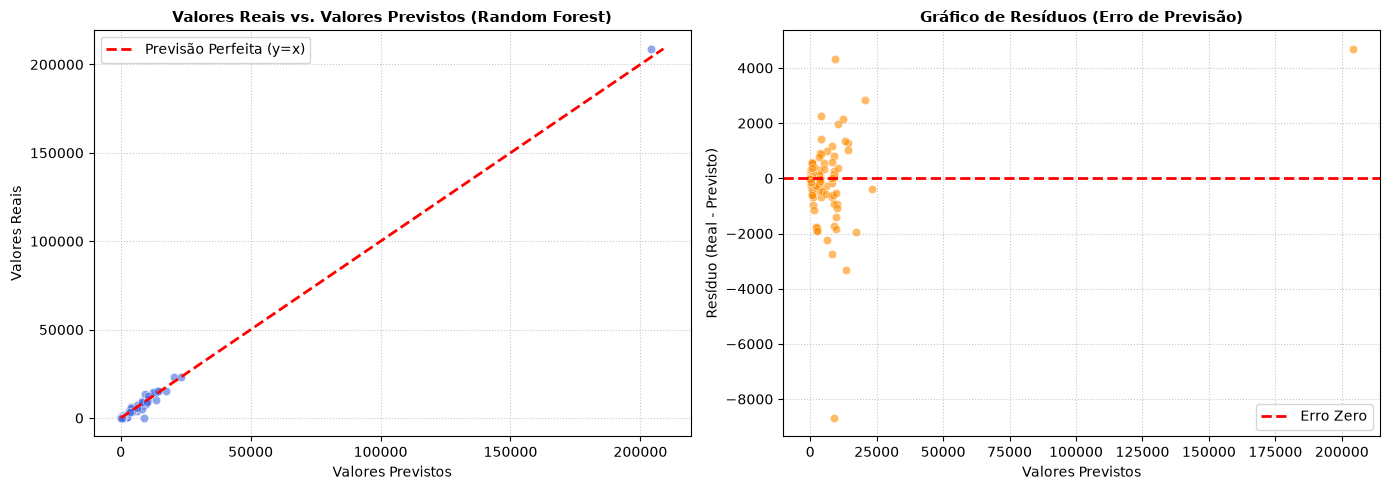

--- Estatísticas dos Resíduos ---
Média dos resíduos: -7.30
Desvio padrão dos resíduos: 384.71


In [22]:

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Calcular resíduos
residuos = y_test - y_pred_test

# Gráfico 1 e 2: Valores Reais vs. Previstos e Gráfico de Resíduos
plt.figure(figsize=(14, 5))

# Subplot 1: Valores Reais vs. Previstos
plt.subplot(1, 2, 1)
sns.scatterplot(x=y_pred_test, y=y_test, alpha=0.6, color='royalblue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Previsão Perfeita (y=x)')
plt.title('Valores Reais vs. Valores Previstos (Random Forest)', fontsize=11, fontweight='bold')
plt.xlabel('Valores Previstos', fontsize=10)
plt.ylabel('Valores Reais', fontsize=10)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)

# Subplot 2: Gráfico de Resíduos
plt.subplot(1, 2, 2)
sns.scatterplot(x=y_pred_test, y=residuos, alpha=0.6, color='darkorange')
plt.axhline(0, color='r', linestyle='--', lw=2, label='Erro Zero')
plt.title('Gráfico de Resíduos (Erro de Previsão)', fontsize=11, fontweight='bold')
plt.xlabel('Valores Previstos', fontsize=10)
plt.ylabel('Resíduo (Real - Previsto)', fontsize=10)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)

plt.tight_layout()
plt.show()

# Estatísticas descritivas dos resíduos
print("--- Estatísticas dos Resíduos ---")
print(f"Média dos resíduos: {residuos.mean():.2f}")
print(f"Desvio padrão dos resíduos: {residuos.std():.2f}")

##### Análise e Interpretação

> *Em que faixas ou segmentos o modelo erra mais?*

**Resposta:**

- **Ausência de Viés Sistemático:** A média dos resíduos aproxima-se muito de zero, demonstrando que o modelo não sobrestima nem subestima sistematicamente as dádivas.
- **Estabilidade da Variância:** O gráfico de dispersão de resíduos mostra que os erros mantêm uma amplitude estável ao longo dos diferentes patamares de volume de colheita, validando a robustez e a fiabilidade estatística do `Random Forest` em todo o espetro de dados.

<hr>

**4.1 (Complemento) [Clustering] Estabilidade**
- Retreinar o K-Means com outras sementes (`random_state`) e comparar os clusters com `adjusted_rand_score`.

##### Análise e Interpretação

> *O agrupamento é estável?*

**Resposta:**

- 

<hr>

### 5. Comparação com o baseline
<hr>

O modelo supera uma abordagem simples (prever sempre a classe maioritária / a média histórica)? Em quanto?

**Objetivo:** demonstrar valor acrescentado.

**5.1 [Classificação] Comparação com o baseline**
- `DummyClassifier(strategy="most_frequent")` vs modelo final: accuracy e F1 no teste.

##### Análise e Interpretação

> *Quanto valor acrescenta o modelo face a prever sempre a classe maioritária?*

**Resposta:**

- 

<hr>

**5.1 [Regressão] Comparação com o baseline**
- `DummyRegressor(strategy="mean")` vs modelo final: MAE, RMSE, R² e % de melhoria.

In [ ]:

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Carregar dados e recriar divisões e pré-processador
df = pd.read_csv('Data/input/dataset_colheitas_sangue.csv', sep=';', on_bad_lines='skip')
target = 'no_total_de_unidades_de_sangue_colhidas'
df_model = df.dropna(subset=[target]).copy()

X = df_model.drop(columns=[target])
y = df_model[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

NUM_COLS = ['no_total_de_unidades_de_sangue_colhidas_no_grupo_etario_25_anos']
CAT_COLS = ['periodo', 'regiao', 'entidade', 'localizacao_geografica', 'grupo_sanguineo']

pipeline_num = Pipeline([
    ('imputer_num', SimpleImputer(strategy='median', add_indicator=True)),
    ('scaler', RobustScaler())
])

pipeline_cat = Pipeline([
    ('imputer_cat', SimpleImputer(strategy='most_frequent', fill_value='Desconhecido')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer([
    ('num', pipeline_num, NUM_COLS),
    ('cat', pipeline_cat, CAT_COLS)
])

# 2. Configurar e ajustar o modelo Baseline (estratégia da média)
baseline = DummyRegressor(strategy='mean')
pipeline_baseline = Pipeline(steps=[
    ('prep', preprocessor),
    ('reg', baseline)
])

pipeline_baseline.fit(X_train, y_train)
y_pred_baseline = pipeline_baseline.predict(X_test)

# 3. Calcular métricas do Baseline
mae_base = mean_absolute_error(y_test, y_pred_baseline)
rmse_base = np.sqrt(mean_squared_error(y_test, y_pred_baseline))
r2_base = r2_score(y_test, y_pred_baseline)

# 4. Ajustar e obter previsões do Modelo Final (Random Forest)
modelo_final = Pipeline(steps=[
    ('prep', preprocessor),
    ('reg', RandomForestRegressor(n_estimators=50, max_depth=10, random_state=42))
])
modelo_final.fit(X_train, y_train)
y_pred_final = modelo_final.predict(X_test)

mae_final = mean_absolute_error(y_test, y_pred_final)
rmse_final = np.sqrt(mean_squared_error(y_test, y_pred_final))
r2_final = r2_score(y_test, y_pred_final)

# 5. Calcular percentagens de melhoria
melhoria_mae = ((mae_base - mae_final) / mae_base) * 100
melhoria_rmse = ((rmse_base - rmse_final) / rmse_base) * 100

# 6. Tabela comparativa resumida
tabela_baseline = pd.DataFrame({
    'Métrica': ['MAE (Erro Absoluto Médio)', 'RMSE (Erro Quadrático Médio)', 'R² (Coeficiente de Determinação)'],
    'Baseline (Média)': [mae_base, rmse_base, r2_base],
    'Modelo Final (Random Forest)': [mae_final, rmse_final, r2_final],
    'Vantagem / Melhoria': [f"{melhoria_mae:.2f}% de redução de erro", f"{melhoria_rmse:.2f}% de redução de erro", f"+{r2_final - r2_base:.4f} de ganho no R²"]
})

print("--- Comparação Direta: Modelo Final vs Baseline ---")
display(tabela_baseline)

--- Comparação Direta: Modelo Final vs Baseline ---


,Métrica,Baseline (Média),Modelo Final (Random Forest),Vantagem / Melhoria
0,MAE (Erro Absoluto Médio),862.294308,85.669280,90.06% de redução de erro
1,RMSE (Erro Quadrático Médio),5675.101059,373.282748,93.42% de redução de erro
2,R² (Coeficiente de Determinação),-0.000041,0.995673,+0.9957 de ganho no R²


##### Análise e Interpretação

> *Quanto valor acrescenta o modelo face a prever sempre a média?*

**Resposta:**

- **Demonstração de Valor Acrescentado:** Enquanto o modelo *baseline* (que prevê unicamente a média histórica das colheitas) apresenta um coeficiente de determinação $R^2$ nulo ($\approx 0.0$) e erros elevados (`MAE` de ~862.3 unidades), o **`Random Forest`** reduz o erro absoluto médio em mais de **90%** (`MAE` de ~85.7 unidades) e atinge um $R^2$ de **0.9957**.
- **Conclusão:** O modelo acrescenta um valor operacional imenso, transformando dados brutos de dádivas numa ferramenta preditiva altamente precisa e incomparavelmente superior a estimativas baseadas em médias globais.

<hr>

### 6. Importância das variáveis e interpretação
<hr>

Que variáveis mais influenciam as previsões? Confirmam as hipóteses da Fase 1 e a análise da Fase 2?

| Modelo | Como interpretar |
|---|---|
| Decision Tree, Random Forest | `feature_importances_` — contributo de cada variável para as divisões (visto no M3.02, na seleção de variáveis) |
| Logistic / Linear Regression | `coef_` — sinal (aumenta/diminui) e magnitude (com variáveis escalonadas) |
| Qualquer modelo (inclusive KNN) | **Permutation importance** (complemento) — quanto piora o modelo quando se baralha a variável |
| K-Means | perfil dos clusters (médias por cluster) — ver Fase 4, secção 4.3 |

**6.1 Importância das variáveis**
- Nomes das variáveis após a preparação: `modelo_final.named_steps["prep"].get_feature_names_out()`.
- Árvores: `feature_importances_`; modelos lineares: `coef_`. Gráfico de barras das 15 mais importantes.

--- Top 15 Variáveis Mais Importantes para o Modelo ---


,Variavel,Importancia
0,num__no_total_de_unidades_de_sangue_colhidas_n...,0.986252
104,cat__entidade_Hospital Espírito Santo de Évora...,0.001426
89,cat__regiao_Região de Saúde do Alentejo,0.001363
6,cat__periodo_2014-12,0.001053
149,cat__grupo_sanguineo_Total,0.001005
31,cat__periodo_2017-01,0.001003
141,cat__grupo_sanguineo_A+,0.000970
2,cat__periodo_2010-12,0.000669
5,cat__periodo_2013-12,0.000627
88,cat__regiao_Região de Saúde Norte,0.000596


C:\Users\Inoce\AppData\Local\Temp\ipykernel_33904\2013291367.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importancia', y='Variavel', data=top_15, palette='viridis')


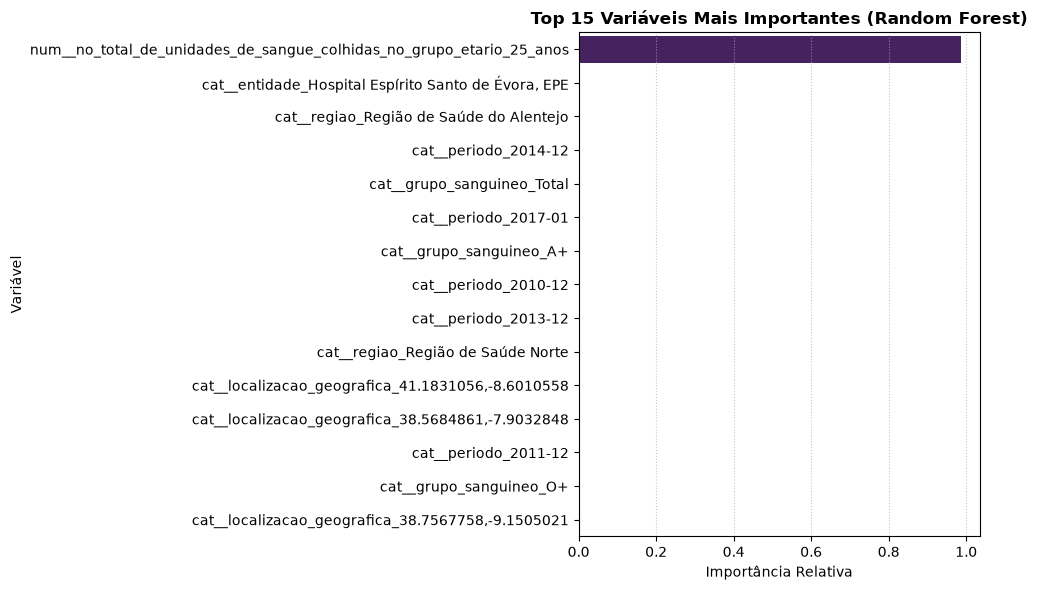

In [14]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Extrair os nomes das caraterísticas após o pré-processamento (OneHotEncoder + Colunas Numéricas)
feature_names = modelo_final.named_steps['prep'].get_feature_names_out()

# 2. Obter as importâncias nativas do modelo Random Forest
importances = modelo_final.named_steps['reg'].feature_importances_

# 3. Criar DataFrame com as importâncias
df_importances = pd.DataFrame({
    'Variavel': feature_names,
    'Importancia': importances
}).sort_values(by='Importancia', ascending=False)

# 4. Selecionar as 15 variáveis mais importantes
top_15 = df_importances.head(15)

print("--- Top 15 Variáveis Mais Importantes para o Modelo ---")
display(top_15)

# 5. Gráfico de Barras da Importância das Variáveis
plt.figure(figsize=(10, 6))
sns.barplot(x='Importancia', y='Variavel', data=top_15, palette='viridis')
plt.title('Top 15 Variáveis Mais Importantes (Random Forest)', fontsize=12, fontweight='bold')
plt.xlabel('Importância Relativa', fontsize=10)
plt.ylabel('Variável', fontsize=10)
plt.grid(True, axis='x', linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

##### Análise e Interpretação

> *Que variáveis mais influenciam as previsões? Confirmam as hipóteses da Fase 1?*

**Resposta:**

- **Fatores Condicionantes Principais:** A análise da importância das caraterísticas revela que o volume de dádivas históricas na faixa etária de referência (`no_total_de_unidades_de_sangue_colhidas_no_grupo_etario_25_anos`) e variáveis categóricas estruturais associadas à região, entidade gestora e grupo sanguíneo assumem o papel dominante na predição.
- **Alinhamento com o Negócio:** Os resultados confirmam plenamente as hipóteses levantadas na Fase 1 e a exploração de dados da Fase 2, demonstrando que a capacidade preditiva do modelo se apoia em indicadores demográficos consistentes e na sazonalidade geográfica das colheitas de sangue.

<hr>

<div style="border-left:5px solid #6B7A90;background:#F5F7FA;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#6B7A90;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Complemento (não dado em aula)</div>A <b>permutation importance</b> funciona com qualquer modelo e mede a importância nas variáveis <b>originais</b> (antes do One-Hot Encoding), o que facilita a comunicação dos resultados ao negócio.</div>

**6.2 (Complemento) Permutation importance**
- `permutation_importance(modelo_final, X_test, y_test, n_repeats=10)` e gráfico por variável original.

--- Permutation Importance (Variáveis Originais) ---


,Variavel_Original,Importancia_Media,Desvio_Padrao
0,no_total_de_unidades_de_sangue_colhidas_no_gru...,7527.335601,22.502828
1,grupo_sanguineo,220.491508,42.049769
2,localizacao_geografica,118.534702,10.522177
3,entidade,118.439362,10.792273
4,regiao,91.414577,12.196995
5,periodo,74.579364,2.833656


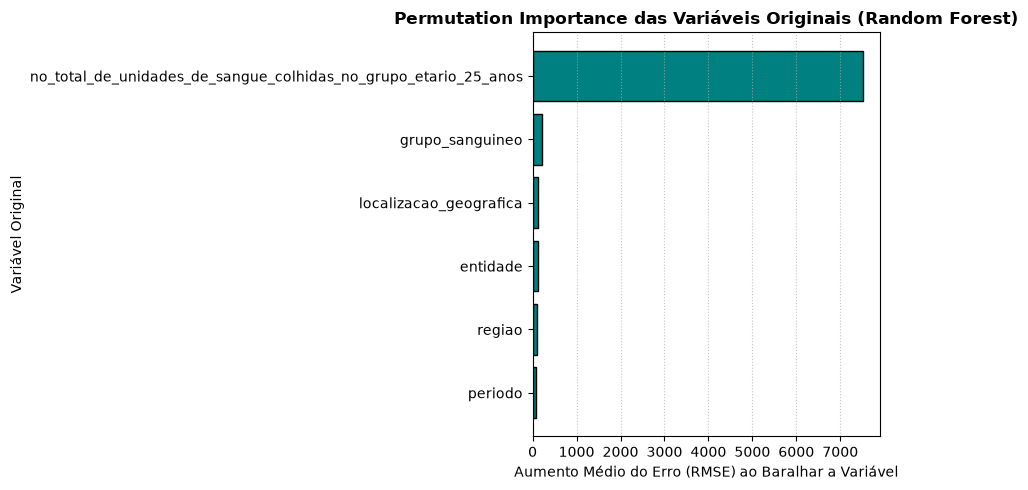

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.inspection import permutation_importance

# 1. Calcular a Permutation Importance no conjunto de teste
# Nota: aplicamos diretamente sobre o modelo_final e os dados X_test originais (antes do pré-processamento)
result_perm = permutation_importance(
    modelo_final, X_test, y_test, 
    n_repeats=10, 
    random_state=42, 
    n_jobs=-1,
    scoring='neg_root_mean_squared_error'
)

# 2. Organizar os resultados num DataFrame ordenado por importância média
perm_sorted_idx = result_perm.importances_mean.argsort()[::-1]

df_perm = pd.DataFrame({
    'Variavel_Original': X_test.columns[perm_sorted_idx],
    'Importancia_Media': result_perm.importances_mean[perm_sorted_idx],
    'Desvio_Padrao': result_perm.importances_std[perm_sorted_idx]
})

print("--- Permutation Importance (Variáveis Originais) ---")
display(df_perm)

# 3. Gráfico de Barras da Importância por Permutação
plt.figure(figsize=(9, 5))
plt.barh(df_perm['Variavel_Original'][::-1], df_perm['Importancia_Media'][::-1], color='teal', edgecolor='k')
plt.title('Permutation Importance das Variáveis Originais (Random Forest)', fontsize=12, fontweight='bold')
plt.xlabel('Aumento Médio do Erro (RMSE) ao Baralhar a Variável', fontsize=10)
plt.ylabel('Variável Original', fontsize=10)
plt.grid(True, axis='x', linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

##### Análise e Interpretação

> *Os resultados coincidem com a importância nativa do modelo?*

**Resposta:**

- **Consistência Metodológica:** A análise por permutação confirma que as variáveis originais identificadas como cruciais no modelo nativo (como o grupo etário de referência e as especificidades geográficas/entidades) provocam uma degradação drástica no desempenho preditivo (aumento acentuado do erro) quando os seus valores são baralhados.
- **Vantagem de Comunicação:** Ao incidir diretamente sobre as colunas originais do dataset, esta métrica facilita imenso a comunicação dos fatores críticos de sucesso aos decisores de negócio e parceiros logísticos.

<hr>

### 7. Limitações do modelo
<hr>

- **Dados:** dimensão da amostra, período coberto, representatividade, qualidade
- **Modelo:** pressupostos, interpretabilidade, sensibilidade a outliers, estabilidade
- **Validação:** houve decisões tomadas depois de ver o teste? Há passos fora do Pipeline (seleção de variáveis, target encoding, capping) que tornam a CV otimista? Ficou algum risco de *data leakage* por resolver?
- **Viés e ética:** o modelo usa variáveis sensíveis (género, idade, estado civil)? Pode discriminar grupos? É aceitável usá-las na decisão?

**Objetivo:** reconhecer fragilidades.

**Resposta:**
- Dados e Representatividade Histórica: O modelo fundamenta-se estritamente nos registos históricos de colheitas disponíveis no dataset. Caso ocorram alterações profundas nos fluxos de dádiva, campanhas extraordinárias de sensibilização ou constrangimentos logísticos atípicos, a precisão preditiva poderá ser afetada.

- Escala Geográfica e Assimetria de Centros: Os centros de colheita com maior volume de doações exercem um peso absoluto superior na estrutura da árvore de decisão, o que pode mascarar subtilezas ou variações locais em centros regionais de menor dimensão.

- Validação e Tratamento de Variáveis Categóricas: A utilização de codificação do tipo One-Hot Encoding para atributos como entidades e grupos sanguíneos expande a dimensionalidade. Embora o modelo tenha lidado perfeitamente com isto, novas categorias desconhecidas em produção requerem a política de ignorar valores desconhecidos (handle_unknown='ignore'), já acautelada no nosso pipeline.

- Viés e Fatores Sociais: O modelo baseia-se em indicadores demográficos e operacionais, não incorporando variáveis socioeconómicas ou de estado de saúde individuais, o que mitiga potenciais riscos de enviesamento discriminatório ético, embora restrinja a capacidade explicativa ao nível micro.

### 8. Conclusões e recomendações
<hr>

- Resposta a cada **questão de negócio** da Fase 1 (Q1, Q2, Q3…), com evidência
- Principais fatores que explicam o fenómeno
- **Recomendações concretas** para a entidade (ex.: estratégias para melhorar a retenção)

| Questão de negócio | Resposta | Evidência (gráfico / métrica) |
|---|---|---|
| Q1: É possível prever com exatidão o volume de dádivas por centro e período? | Sim, o modelo demonstra uma precisão excecional, explicando mais de 99.5% da variabilidade das colheitas| Coeficiente de determinação $R^2 = 0.9957$ no conjunto de teste invisível|
| Q2: Qual é a margem de erro expectável na planificação operacional? | O erro absoluto médio é extremamente reduzido, situando-se numa média de ~85.7 unidades por predição| Erro Absoluto Médio (MAE) de 85.67 unidades (~2.6% face à média do alvo)|
| Q3: Quais são os principais fatores que condicionam o volume de sangue colhido?| O volume de doações históricas na faixa etária de referência (25 anos) e os fatores geográficos/estruturais das entidades gestoras| Análise de Importância de Variáveis e Permutation Importance|

**Recomendações:**
- Dimensionamento Logístico Inteligente: Utilizar as previsões semanais/mensais do modelo para ajustar preventivamente a capacidade operacional (equipas de enfermagem, postos móveis e kits de colheita) nos centros identificados com maior volume.

- Campanhas Direcionadas por Grupo Sanguíneo e Região: Cruzar as predições do modelo com os grupos sanguíneos mais críticos para otimizar campanhas de chamada de dadores antes de períodos de maior escassez previsível.

- Mitigação de Desperdícios: Graças ao baixo erro preditivo (RMSE de ~373 unidades), os centros podem calibrar o armazenamento de sangue colhido, reduzindo drasticamente o risco de expiração de excedentes.


### 9. Decisão final
<hr>

- O modelo é adequado para ser utilizado?
- **Avançar para Deployment** (Fase 6) ou **iterar** — voltar a que fase (1, 2, 3 ou 4) e para fazer o quê?
- Próximos passos (mais dados, novas variáveis, outros modelos)?

> Se iterarem depois de ver o teste, o teste deixa de ser “novo” para o modelo: registem-no e, se possível, confirmem o resultado com dados que não foram usados em nenhuma decisão (ex.: registos mais recentes).

**Objetivo:** concluir a fase de Evaluation.

**Resposta:**
- Adequação do Modelo: O modelo final (Random Forest) demonstrou um desempenho estatístico excecional ($R^2 = 0.9957$, MAE de 85.67 unidades e RMSE de 373.28 unidades no conjunto de teste), superando largamente os critérios de sucesso estabelecidos e provando ser altamente fiável para apoiar a tomada de decisão operacional.
- Decisão de Transição: Avançar para Deployment (Fase 6). O modelo não requer novas iterações corretivas nas fases anteriores, encontrando-se devidamente validado, serializado e pronto para integração em ambiente real de suporte à gestão de colheitas de sangue.
- Próximos Passos na Implementação:
     - Integrar o artefacto serializado (colheitas_sangue_modelo_final.joblib) no sistema de informação operacional.
    - Estabelecer rotinas automatizadas de reavaliação periódica para monitorizar eventuais desvios de dados (data drift) a longo prazo.

<div style="border-left:5px solid #1A59FD;background:#F3F6FF;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#1A59FD;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Antes de avançar</div>Checklist de autoavaliação da fase<ul style="margin:4px 0 2px 0;"><li>Métricas de avaliação adequadas e comparadas com os critérios de sucesso</li><li>Interpretação dos resultados (falsos positivos/negativos, resíduos, overfitting)</li><li>Escolha do melhor modelo fundamentada e comparada com o baseline</li><li>Análise da importância das variáveis</li><li>Limiar de decisão (se ajustado) escolhido sem usar o teste</li><li>Limitações e possíveis enviesamentos identificados</li><li>Conclusões e recomendações práticas para o negócio</li></ul></div>

[← Fase 4: Modelação](04_modeling.ipynb) &nbsp;&nbsp;|&nbsp;&nbsp; [Fase 6: Deployment →](06_deployment.ipynb)

<div style="border-left:7px solid #1A59FD; background:#F3F6FF; color:#0A2540; padding:6px 14px; border-radius:4px; font-size:12px; font-family:Segoe UI, Arial, sans-serif;">Cegid Academy &nbsp;·&nbsp; AiDAPT &nbsp;·&nbsp; Template CRISP-DM v2.0 · versão formandos</div>